In [149]:
import numpy as np 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression

In [150]:
df = pd.read_csv("/kaggle/input/datasets/thenightowl009/connquant/NVDA.csv")

In [151]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFirst five rows:")
display(df.head())

Dataset dimensions: (1941, 6)

Column names:
['timestamp', 'open', 'high', 'low', 'close', 'volume']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  1941 non-null   object 
 1   open       1941 non-null   float64
 2   high       1941 non-null   float64
 3   low        1941 non-null   float64
 4   close      1941 non-null   float64
 5   volume     1941 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 91.1+ KB

First five rows:


,timestamp,open,high,low,close,volume
0,2020-03-23 09:31:00,204.1600,204.1600,204.16,204.1600,568408
1,2020-03-23 09:32:00,204.3191,204.5065,200.56,200.7100,81709
2,2020-03-23 09:33:00,200.7299,206.1234,200.69,205.3801,59476
3,2020-03-23 09:34:00,205.4900,208.4999,204.12,207.7100,69771
4,2020-03-23 09:35:00,205.8200,205.8200,205.82,205.8200,57105


In [152]:
print("Duplicate value: \n")
df.duplicated()



Duplicate value: 



0       False
1       False
2       False
3       False
4       False
        ...  
1936    False
1937    False
1938    False
1939    False
1940    False
Length: 1941, dtype: bool

In [153]:
print("column: \n")
df[["open", "high"]].head(10)


column: 



,open,high
0,204.1600,204.1600
1,204.3191,204.5065
2,200.7299,206.1234
3,205.4900,208.4999
4,205.8200,205.8200
5,206.7661,206.8798
6,206.4600,207.8500
7,206.1692,206.1692
8,202.0200,202.0200
9,200.1850,200.8650


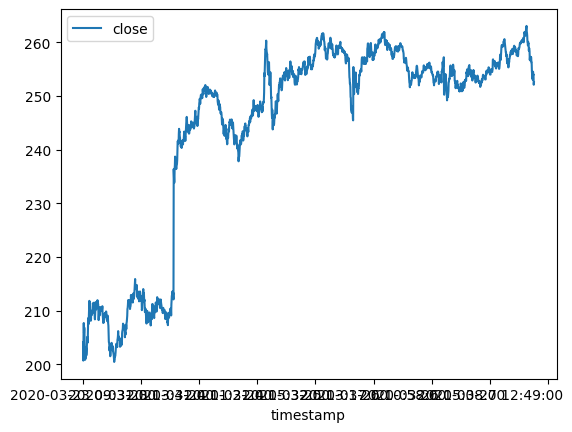

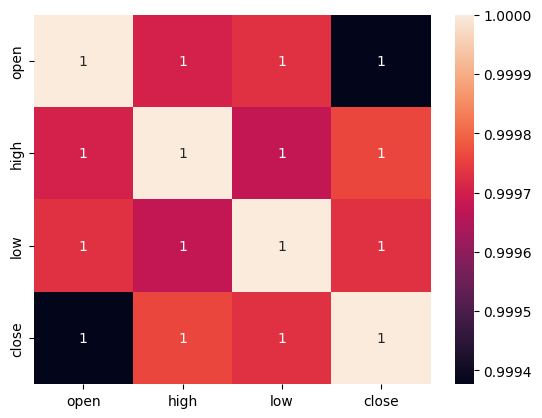

In [154]:
df.plot(x="timestamp", y="close")
plt.show()

sns.heatmap(df[['open', 'high', 'low', 'close']].corr(), annot=True)
plt.show()


In [155]:
invalid_ohlc = df[
    (df['high'] < df[['open', 'close']].max(axis=1)) |
    (df['low'] > df[['open', 'close']].min(axis=1)) |
    (df['high'] < df['low'])
]

print("Number of suspicious OHLC rows:", len(invalid_ohlc))


Number of suspicious OHLC rows: 0


In [156]:
df["daily_return"] = df["close"].pct_change()*100
display(df[["timestamp","close", "daily_return"]].head(10))

print("largest daily return:")
display(df.nlargest(5, 'daily_return')[['timestamp', 'close', 'daily_return']])

print("largest daily losses:")
display(df.nsmallest(5, 'daily_return')[['timestamp', 'close', 'daily_return']])

,timestamp,close,daily_return
0,2020-03-23 09:31:00,204.1600,NaN
1,2020-03-23 09:32:00,200.7100,-1.689851
2,2020-03-23 09:33:00,205.3801,2.326790
3,2020-03-23 09:34:00,207.7100,1.134433
4,2020-03-23 09:35:00,205.8200,-0.909922
5,2020-03-23 09:36:00,206.8798,0.514916
6,2020-03-23 09:37:00,206.5102,-0.178654
7,2020-03-23 09:38:00,202.5500,-1.917678
8,2020-03-23 09:39:00,201.3200,-0.607257
9,2020-03-23 09:40:00,200.8650,-0.226008


largest daily return:


,timestamp,close,daily_return
390,2020-03-24 09:31:00,236.4000,11.451605
1163,2020-03-26 09:31:00,255.4200,4.049210
2,2020-03-23 09:33:00,205.3801,2.326790
780,2020-03-25 09:32:00,254.2900,1.432355
21,2020-03-23 09:52:00,206.9401,1.411399


largest daily losses:


,timestamp,close,daily_return
1553,2020-03-27 09:31:00,250.3000,-2.697870
7,2020-03-23 09:38:00,202.5500,-1.917678
1,2020-03-23 09:32:00,200.7100,-1.689851
816,2020-03-25 10:08:00,243.7922,-1.080441
31,2020-03-23 10:02:00,208.4317,-1.057771


In [157]:
daily_volatility = df["daily_return"].std()
print("daily volatility:", daily_volatility,"%")

daily volatility: 0.3967832209773898 %


In [158]:
volatility_20d = df["daily_return"].rolling(window = 10).std()
print("rolling_volatility:", volatility_20d,"%")

rolling_volatility: 0            NaN
1            NaN
2            NaN
3            NaN
4            NaN
          ...   
1936    0.361145
1937    0.362903
1938    0.364735
1939    0.410816
1940    0.421827
Name: daily_return, Length: 1941, dtype: float64 %


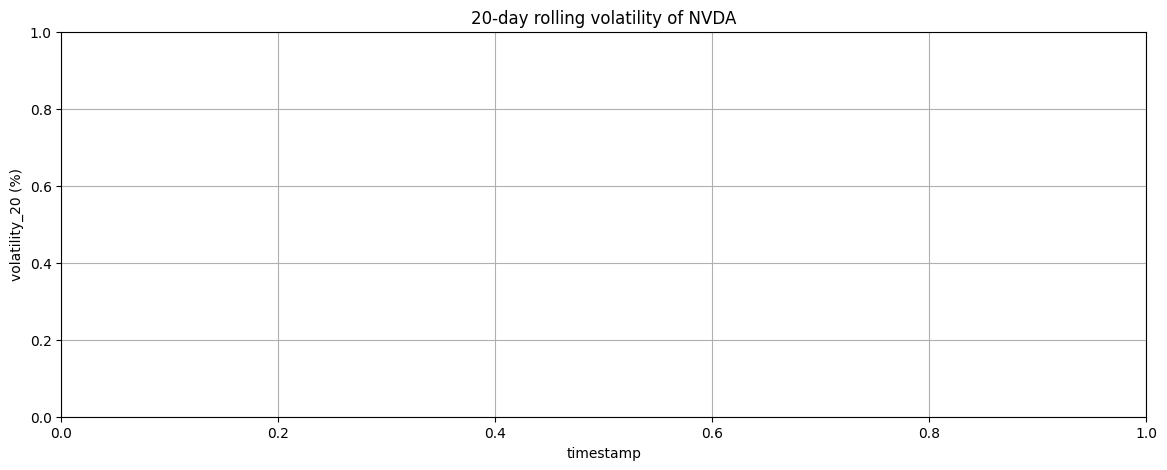

In [159]:
plt.figure(figsize=(14, 5))

plt.title('20-day rolling volatility of NVDA')
plt.xlabel('timestamp')
plt.ylabel('volatility_20 (%)')

plt.grid(True)
plt.show()